# NDVI spring phenology + relative IA45 — grouped classification benchmark

**Plot-level fitting/evaluation only. No raster mapping or GeoTIFF outputs.** This notebook compares the established relative IA45 representation with six K2-NDVI peak-to-trough descriptors, using matched observations and identical grouped out-of-fold splits. The K5 response comes exclusively from the parent FCM assignment table, **not** older K8 membership fields. K4 merges ARTR and non-ARTR shrub; K5 retains the separate shrub child labels. Phenology failures are **not** removed: missing predictors are imputed separately inside each training fold.

Prerequisites: existing field IA45 CSV, K5 assignment CSV, K2 annual intercept/amplitude/phase TIFFs, `rasterio`, `pyproj`, `scikit-learn`. The 2026 dataset is used automatically if field rows, K5 assignments, and the raster exist. **Verify phase convention/time origin against the Earth Engine harmonic export before interpreting DOY features.**

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

VEG_TRAINING_CSV = Path(r"A:\NCA_DATA\Validation\Supervised_State_Classification\FieldVeg_K2_IA45_Training.csv")
K5_ASSIGNMENTS_CSV = Path(r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived\NCA_FCM_K5_m1p33_parent_assignments.csv")
HARMONIC_ROOT = Path(r"A:\NCA_DATA\S2_Harmonics")
VEG_YEARS = [2016, 2018, 2025, 2026]
X_COL, Y_COL, POINT_CRS = 'Easting', 'Northing', 'EPSG:26911'
RANDOM_STATE, N_SPLITS = 42, 5
MIN_ABS_BETA0, MIN_A1 = 1e-6, 1e-6
# Match the existing phenology notebook. Verify against GEE export.
PHASE_CONVENTION = 'cos_minus'
PHASE_UNITS = 'radians'
TIME_ORIGIN_DOY = 1
SPRING_PEAK_WINDOW = (30, 180)
SUMMER_TROUGH_END_DOY = 300
MAX_DECLINE_DAYS = 180
MIN_PEAK_PROMINENCE_FRACTION = 0.10
MIN_RANGE = 0.025
DOY = np.arange(1, 366)
PHENO_COLS = ['spring_peak_doy','summer_min_doy','decline_duration_days',
              'decline_magnitude_ndvi','mean_decline_rate_ndvi_day',
              'max_decline_rate_ndvi_day']
K5_CODES = [1,2,3,4,5]
K4_CODES = [1,2,4,5]
K5_LABELS = {1:'PBG', 2:'ARTR', 3:'Non-ARTR shrub', 4:'Exotic forb', 5:'EAG'}
K4_LABELS = {1:'PBG', 2:'SHRUB', 4:'Exotic forb', 5:'EAG'}
# Switch to ['extra_trees', 'random_forest'] for both baseline comparisons.
MODELS_TO_RUN = ['extra_trees']
print('NO wall-to-wall inference; plot sampling and fitting only.')

NO wall-to-wall inference; plot sampling and fitting only.


In [2]:
# =============================================================================
# 2. LOAD FIELD OPTICAL DATA + K5 LABELS
# =============================================================================

for path in [
    VEG_TRAINING_CSV,
    K5_ASSIGNMENTS_CSV,
]:
    if not path.exists():
        raise FileNotFoundError(path)

veg = pd.read_csv(
    VEG_TRAINING_CSV,
    low_memory=False,
).drop(
    columns=["Unnamed: 0"],
    errors="ignore",
)

k5 = pd.read_csv(
    K5_ASSIGNMENTS_CSV,
    low_memory=False,
).drop(
    columns=["Unnamed: 0"],
    errors="ignore",
)


def normalize_plot_id(x):
    s = str(x).strip()
    if s.endswith(".0"):
        s = s[:-2]
    return s


# Field table uses PlotID in the established supervised workflow.
if "PlotID" not in veg.columns:
    raise KeyError("Field optical table must contain PlotID.")

# K5 assignment table inherited the vegetation master; it normally uses Plot.
if "Plot" in k5.columns:
    K5_PLOT_COL = "Plot"
elif "PlotID" in k5.columns:
    K5_PLOT_COL = "PlotID"
else:
    raise KeyError("K5 assignment table must contain Plot or PlotID.")

for df in [veg, k5]:
    df["Year"] = pd.to_numeric(
        df["Year"],
        errors="coerce",
    )

veg = veg.loc[
    veg["Year"].isin(VEG_YEARS)
].copy()

k5 = k5.loc[
    k5["Year"].isin(VEG_YEARS)
].copy()

veg["Year"] = veg["Year"].astype(int)
k5["Year"] = k5["Year"].astype(int)

veg["_join_plot"] = veg["PlotID"].map(normalize_plot_id)
k5["_join_plot"] = k5[K5_PLOT_COL].map(normalize_plot_id)

if "parent_cluster_k5" not in k5.columns:
    raise KeyError(
        "K5 assignment table must contain parent_cluster_k5."
    )

k5["parent_cluster_k5"] = pd.to_numeric(
    k5["parent_cluster_k5"],
    errors="coerce",
)

k5 = k5.loc[
    k5["parent_cluster_k5"].isin(K5_CODES)
].copy()

k5["parent_cluster_k5"] = k5["parent_cluster_k5"].astype(int)

JOIN_KEYS = ["_join_plot", "Year"]

if veg.duplicated(JOIN_KEYS).any():
    dup = veg.loc[
        veg.duplicated(JOIN_KEYS, keep=False),
        JOIN_KEYS,
    ].head(20)
    raise ValueError(
        "Field optical table contains duplicate normalized Plot-Year keys.\n"
        + dup.to_string(index=False)
    )

if k5.duplicated(JOIN_KEYS).any():
    dup = k5.loc[
        k5.duplicated(JOIN_KEYS, keep=False),
        JOIN_KEYS,
    ].head(20)
    raise ValueError(
        "K5 assignment table contains duplicate normalized Plot-Year keys.\n"
        + dup.to_string(index=False)
    )

k5_keep = [
    "_join_plot",
    "Year",
    "parent_cluster_k5",
]

for c in [
    "max_membership_k5",
    "membership_margin_k5",
]:
    if c in k5.columns:
        k5_keep.append(c)

merged = veg.merge(
    k5[k5_keep],
    on=JOIN_KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)

unmatched = merged.loc[
    merged["_merge"].ne("both")
].copy()

print("Field optical rows in vegetation years:", len(veg))
print("Matched to K5 labels:                  ", int((merged["_merge"] == "both").sum()))
print("Unmatched field rows:                  ", len(unmatched))

if len(unmatched) > 0:
    display(
        unmatched[
            ["PlotID", "Year", "_join_plot"]
        ].head(30)
    )

veg = (
    merged.loc[
        merged["_merge"].eq("both")
    ]
    .drop(columns=["_merge"])
    .reset_index(drop=True)
)

veg["parent_cluster_k5"] = veg["parent_cluster_k5"].astype(int)
veg["k5_label"] = veg["parent_cluster_k5"].map(K5_LABELS)

print("\nK5 training-label counts:")
display(
    veg.groupby(
        ["parent_cluster_k5", "k5_label"],
        as_index=False,
    )
    .size()
    .rename(columns={"size": "n"})
)

print("\nYear counts:")
display(
    veg["Year"]
    .value_counts()
    .sort_index()
    .rename("n")
    .to_frame()
)


Field optical rows in vegetation years: 479
Matched to K5 labels:                   479
Unmatched field rows:                   0

K5 training-label counts:


,parent_cluster_k5,k5_label,n
0,1,PBG,109
1,2,ARTR,36
2,3,Non-ARTR shrub,109
3,4,Exotic forb,93
4,5,EAG,132



Year counts:


,n
Year,
2016,255
2018,106
2025,118


In [3]:
# =============================================================================
# 3. ALIGN IA45 AND CONSTRUCT RELATIVE-HARMONIC PREDICTORS
# =============================================================================

def normalize_feature_name(x):
    return str(x).strip().lower()


def parse_ia_feature(name):
    """Parse IA names in either term_variable or variable_term orientation.

    Established raster/field conventions include constant_B2, amp1_B2,
    amp2_B2. Also accepts B2_constant, B2_amp1 and 'intercept' variants.
    """
    key = normalize_feature_name(name)
    term_pattern = r"(?:intercept|constant|beta0|amp(?:litude)?[_-]?[12])"
    for pattern, term_first in (
        (rf"({term_pattern})[_-](.+)", True),
        (rf"(.+)[_-]({term_pattern})", False),
    ):
        match = re.fullmatch(pattern, key)
        if match is None:
            continue
        term, variable = match.groups() if term_first else match.groups()[::-1]
        if not variable:
            continue
        if term in ("intercept", "constant", "beta0"):
            order = "beta0"
        else:
            order = "A1" if term[-1] == "1" else "A2"
        return variable, order
    return None


# Field data are authoritative for the 15 original variable triples.
triples = {}
for col in veg.columns:
    parsed = parse_ia_feature(col)
    if parsed is None:
        continue
    variable, term = parsed
    if term in triples.setdefault(variable, {}):
        raise ValueError(f"Duplicate {term} column for {variable}")
    triples[variable][term] = col

if len(triples) != 15 or any(
    set(fields) != {"beta0", "A1", "A2"} for fields in triples.values()
):
    raise ValueError(
        "Expected 15 complete beta0/A1/A2 triples; discovered:\n"
        + "Candidate IA columns: " + repr([c for c in veg.columns if re.search(r"constant|intercept|amp|beta0", str(c), re.I)][:60]) + "\n"
        + "\n".join(f"{variable}: {fields}" for variable, fields in triples.items())
    )

VARIABLES = list(triples)
SOURCE_IA_COLS = [
    triples[var][term]
    for var in VARIABLES
    for term in ("beta0", "A1", "A2")
]
FEATURE_NAMES = [
    f"{var}__{term}"
    for var in VARIABLES
    for term in ("beta0", "A1_over_beta0", "A2_over_A1")
]


def transform_relative_harmonics(raw):
    """Transform (n,45) original baseline/amplitude data; return (n,45), valid mask."""
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != len(SOURCE_IA_COLS):
        raise ValueError(f"Expected (n,{len(SOURCE_IA_COLS)}) original IA predictors; got {raw.shape}")
    cube = raw.reshape(-1, len(VARIABLES), 3)
    beta0, a1, a2 = cube[:, :, 0], cube[:, :, 1], cube[:, :, 2]
    valid = (
        np.isfinite(cube).all(axis=(1, 2))
        & (np.abs(beta0) > MIN_ABS_BETA0).all(axis=1)
        & (a1 > MIN_A1).all(axis=1)
    )
    transformed = np.full((len(raw), len(VARIABLES), 3), np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        transformed[:, :, 0] = beta0
        transformed[:, :, 1] = a1 / beta0
        transformed[:, :, 2] = a2 / a1
    flat = transformed.reshape(-1, len(FEATURE_NAMES))
    valid &= np.isfinite(flat).all(axis=1)
    return flat, valid


X_raw = veg[SOURCE_IA_COLS].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
X_rel_all, valid_rel = transform_relative_harmonics(X_raw)
print(f"Complete cases for ratios: {valid_rel.sum():,} / {len(valid_rel):,}")
print("Excluded observations:", int((~valid_rel).sum()))
print("Excluded by year:")
print(veg.assign(valid_ratio=valid_rel).groupby("Year")["valid_ratio"].agg(["sum", "count"]))

# Keep the response, group identifiers and predictor matrix row-aligned.
veg = veg.loc[valid_rel].reset_index(drop=True)
X_rel = X_rel_all[valid_rel]
y = ("K5::" + veg["parent_cluster_k5"].astype(str)).to_numpy()
groups = veg["PlotID"].astype(str).to_numpy()
print("Training matrix:", X_rel.shape)
print("Classes:", sorted(np.unique(y)))
print("Variables and original source triples:")
for var in VARIABLES:
    print(var, triples[var])


Complete cases for ratios: 479 / 479
Excluded observations: 0
Excluded by year:
      sum  count
Year            
2016  255    255
2018  106    106
2025  118    118
Training matrix: (479, 45)
Classes: ['K5::1', 'K5::2', 'K5::3', 'K5::4', 'K5::5']
Variables and original source triples:
b2 {'beta0': 'constant_B2', 'A1': 'amp1_B2', 'A2': 'amp2_B2'}
b3 {'beta0': 'constant_B3', 'A1': 'amp1_B3', 'A2': 'amp2_B3'}
b4 {'beta0': 'constant_B4', 'A1': 'amp1_B4', 'A2': 'amp2_B4'}
b5 {'beta0': 'constant_B5', 'A1': 'amp1_B5', 'A2': 'amp2_B5'}
b6 {'beta0': 'constant_B6', 'A1': 'amp1_B6', 'A2': 'amp2_B6'}
b7 {'beta0': 'constant_B7', 'A1': 'amp1_B7', 'A2': 'amp2_B7'}
b8 {'beta0': 'constant_B8', 'A1': 'amp1_B8', 'A2': 'amp2_B8'}
b8a {'beta0': 'constant_B8A', 'A1': 'amp1_B8A', 'A2': 'amp2_B8A'}
b11 {'beta0': 'constant_B11', 'A1': 'amp1_B11', 'A2': 'amp2_B11'}
b12 {'beta0': 'constant_B12', 'A1': 'amp1_B12', 'A2': 'amp2_B12'}
ndvi {'beta0': 'constant_NDVI', 'A1': 'amp1_NDVI', 'A2': 'amp2_NDVI'}
ndmi {'beta0

In [4]:
# Original IA45 labels and feature matrix. Do not remove observations after this step.
y5 = veg['parent_cluster_k5'].to_numpy(dtype=int)
y4 = np.where(np.isin(y5, [2, 3]), 2, y5)
print('Common IA45 study sample:', len(veg))
print('K5 support:', pd.Series(y5).value_counts().sort_index().to_dict())

Common IA45 study sample: 479
K5 support: {1: 109, 2: 36, 3: 109, 4: 93, 5: 132}


In [5]:
# Sample only five NDVI bands at the SAME IA45-valid observations.
# Uses existing raster band names: constant_NDVI, amp1_NDVI, phase1_NDVI,
# amp2_NDVI, phase2_NDVI.
def annual_path(year):
    return HARMONIC_ROOT / str(year) / f'{year}_K2_InterceptAmpPhase_nobs_RMSE.tif'

def band_names(src):
    return [str(x or f'band_{i}').strip() for i, x in enumerate(src.descriptions, 1)]

def resolve_ndvi_bands(src):
    # Requires explicit NDVI intercept, amplitude 1/2 and phase 1/2.
    # Prevents silently using phase from a different index/order.
    names = band_names(src)
    groups = {
        'beta0': [r'^(constant|intercept|beta0)[_-]ndvi$', r'^ndvi[_-](constant|intercept|beta0)$'],
        'a1': [r'^(amp1|amplitude1|amp_1)[_-]ndvi$', r'^ndvi[_-](amp1|amplitude1|amp_1)$'],
        'a2': [r'^(amp2|amplitude2|amp_2)[_-]ndvi$', r'^ndvi[_-](amp2|amplitude2|amp_2)$'],
        'p1': [r'^(phase1|phase_1|phi1|phi_1)[_-]ndvi$', r'^ndvi[_-](phase1|phase_1|phi1|phi_1)$'],
        'p2': [r'^(phase2|phase_2|phi2|phi_2)[_-]ndvi$', r'^ndvi[_-](phase2|phase_2|phi2|phi_2)$'],
    }
    idx = {}
    for key, patterns in groups.items():
        match = [i for i,name in enumerate(names, 1) if any(re.fullmatch(pt,name.lower()) for pt in patterns)]
        if len(match) != 1:
            raise ValueError(f'{key}: expected one NDVI band, got {match}. Available NDVI bands: '
                             +repr([(i,s) for i,s in enumerate(names,1) if 'ndvi' in s.lower()]))
        idx[key] = match[0]
    return idx

def sample_year(df, year):
    path=annual_path(year)
    if not path.exists():
        print(f'Skipping {year}: no raster')
        return pd.DataFrame()
    with rasterio.open(path) as ds:
        ix=resolve_ndvi_bands(ds)
        xy=df[[X_COL,Y_COL]].apply(pd.to_numeric,errors='coerce').to_numpy(float)
        if not np.isfinite(xy).all():
            raise ValueError(f'Invalid plot coordinates for {year}')
        if str(ds.crs) != str(POINT_CRS):
            t=Transformer.from_crs(POINT_CRS,ds.crs,always_xy=True)
            xy=np.array([t.transform(x,y) for x,y in xy])
        coords=list(map(tuple,xy))
        # Only 5 bands at selected points; never reads complete raster.
        vals=np.asarray(list(ds.sample(coords,indexes=list(ix.values()),masked=True)))
        values=np.ma.filled(vals.astype(float),np.nan)
        result=df[['PlotID','Year']].copy().reset_index(drop=True)
        for j,key in enumerate(ix): result[key]=values[:,j]
        result['in_bounds']=[ds.bounds.left<=x<=ds.bounds.right and ds.bounds.bottom<=y<=ds.bounds.top for x,y in coords]
        result.loc[~result['in_bounds'],list(ix)] = np.nan
        return result


frames = []
for year, subset in veg.groupby('Year', sort=True):
    sampled_year = sample_year(subset, int(year))
    if len(sampled_year):
        frames.append(sampled_year)
sampled = (pd.concat(frames, ignore_index=True) if frames
           else pd.DataFrame(columns=['PlotID','Year','beta0','a1','a2','p1','p2']))

def normalized_key(x):
    if pd.isna(x): return pd.NA
    s = str(x).strip()
    return s[:-2] if s.endswith('.0') else s

sampled['_key_plot'] = sampled['PlotID'].map(normalized_key)
sampled['_key_year'] = pd.to_numeric(sampled['Year'], errors='coerce')
veg['_key_plot'] = veg['PlotID'].map(normalized_key)
veg['_key_year'] = pd.to_numeric(veg['Year'], errors='coerce')
if sampled.duplicated(['_key_plot','_key_year']).any():
    raise ValueError('Duplicate sampled plot-year records')
coef_cols = ['beta0','a1','a2','p1','p2']
coefs = veg[['_key_plot','_key_year']].merge(
    sampled[['_key_plot','_key_year',*coef_cols]],
    on=['_key_plot','_key_year'], how='left', validate='one_to_one', sort=False)
print('Complete NDVI coefficients:', coefs[coef_cols].notna().all(axis=1).sum(), '/', len(coefs))

Complete NDVI coefficients: 479 / 479


In [6]:
def reconstruct_ndvi(rec, doy=DOY):
    t = np.asarray(doy, dtype=float) - TIME_ORIGIN_DOY
    theta = 2 * np.pi * t / 365.0
    p1, p2 = float(rec['p1']), float(rec['p2'])
    if PHASE_UNITS == 'degrees':
        p1, p2 = np.deg2rad([p1, p2])
    if PHASE_CONVENTION == 'cos_minus':
        v = rec['beta0'] + rec['a1'] * np.cos(theta - p1) + rec['a2'] * np.cos(2 * theta - p2)
    elif PHASE_CONVENTION == 'cos_plus':
        v = rec['beta0'] + rec['a1'] * np.cos(theta + p1) + rec['a2'] * np.cos(2 * theta + p2)
    elif PHASE_CONVENTION == 'sin_plus':
        v = rec['beta0'] + rec['a1'] * np.sin(theta + p1) + rec['a2'] * np.sin(2 * theta + p2)
    else:
        raise ValueError('Unknown PHASE_CONVENTION')
    return np.asarray(v, dtype=float)


def first_spring_peak_and_trough(v):
    """Find first meaningful spring local maximum and next summer local minimum.

    Extrema use circular neighbors (Fourier curve is periodic), but their selection
    uses explicit calendar-day windows. First qualifying candidate is selected.
    Qualifying means the drop to the NEXT local minimum exceeds a prespecified
    fraction of annual fitted range. This avoids selecting insignificant ripples.
    """
    v = np.asarray(v, dtype=float)
    if v.shape != (365,) or not np.isfinite(v).all():
        return None
    annual_range = float(np.ptp(v))
    if annual_range < MIN_RANGE:
        return None
    maxima = np.flatnonzero((v > np.roll(v, 1)) & (v >= np.roll(v, -1)))
    minima = np.flatnonzero((v < np.roll(v, 1)) & (v <= np.roll(v, -1)))
    for peak in maxima:  # sorted earliest DOY first
        peak_doy = int(peak + 1)
        if not SPRING_PEAK_WINDOW[0] <= peak_doy <= SPRING_PEAK_WINDOW[1]:
            continue
        next_minima = [i for i in minima if
                       peak < i and (i - peak) <= MAX_DECLINE_DAYS
                       and (i + 1) <= SUMMER_TROUGH_END_DOY]
        if not next_minima:
            continue
        trough = int(next_minima[0])
        decline = float(v[peak] - v[trough])
        if decline >= MIN_PEAK_PROMINENCE_FRACTION * annual_range:
            return int(peak), trough
    return None


def phenology_metrics(rec):
    v = reconstruct_ndvi(rec)
    annual_range = float(np.ptp(v))
    event = first_spring_peak_and_trough(v)
    out = {
        'spring_peak_doy': np.nan,
        'summer_min_doy': np.nan,
        'spring_peak_ndvi_fit': np.nan,
        'summer_min_ndvi_fit': np.nan,
        'decline_duration_days': np.nan,
        'decline_magnitude_ndvi': np.nan,
        'mean_decline_rate_ndvi_day': np.nan,
        'max_decline_rate_ndvi_day': np.nan,
        'ndvi_range_fit': annual_range,
        'weak_seasonality': annual_range < MIN_RANGE,
        'valid_spring_decline': event is not None,
        'global_peak_doy_qc': int(np.argmax(v)) + 1,
    }
    if event is None:
        return pd.Series(out)
    peak, trough = event
    duration = trough - peak
    daily_change = np.diff(v[peak:trough+1])
    decline = float(v[peak] - v[trough])
    out.update({
        'spring_peak_doy': peak + 1,
        'summer_min_doy': trough + 1,
        'spring_peak_ndvi_fit': float(v[peak]),
        'summer_min_ndvi_fit': float(v[trough]),
        'decline_duration_days': duration,
        'decline_magnitude_ndvi': decline,
        'mean_decline_rate_ndvi_day': decline / duration,
        'max_decline_rate_ndvi_day': float(-daily_change.min()),
    })
    return pd.Series(out)



pheno_rows=[]
for _, rec in coefs.iterrows():
    if not np.isfinite(rec[coef_cols].to_numpy(dtype=float)).all():
        pheno_rows.append({c: np.nan for c in PHENO_COLS} | {'valid_spring_decline': False})
    else:
        pheno_rows.append(phenology_metrics(rec).to_dict())
phenology = pd.DataFrame(pheno_rows).reset_index(drop=True)
print('Qualifying peak → trough:', int(phenology['valid_spring_decline'].sum()), '/', len(phenology))
display(pd.crosstab(pd.Series(y5,name='K5'),phenology['valid_spring_decline']))
X_pheno = phenology[PHENO_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=float)
X_aug = np.column_stack([X_rel, X_pheno])
FEATURE_SETS = {'relative_IA45': X_rel, 'relative_IA45_plus_NDVI6_IA51': X_aug}
print({k:v.shape for k,v in FEATURE_SETS.items()})

Qualifying peak → trough: 448 / 479


valid_spring_decline,False,True
K5,,
1,11,98
2,3,33
3,8,101
4,8,85
5,1,131


{'relative_IA45': (479, 45), 'relative_IA45_plus_NDVI6_IA51': (479, 51)}


In [7]:
# Paired grouped folds. Same rows, same folds, same labels for IA45 and IA51.
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv.split(X_rel, y4, groups))
for f, (train, test) in enumerate(CV_SPLITS, 1):
    assert set(groups[train]).isdisjoint(set(groups[test]))
    assert set(np.unique(y4[train])) == set(K4_CODES)
    assert {2,3}.issubset(set(y5[train]))
    print(f'Fold {f}: train={len(train)}, test={len(test)}, shrub train={np.isin(y5[train],[2,3]).sum()}')

MODELS = {
 'extra_trees': ExtraTreesClassifier(n_estimators=800, max_features='sqrt',
     min_samples_leaf=2, class_weight='balanced', bootstrap=False,
     random_state=RANDOM_STATE, n_jobs=-1),
 'random_forest': RandomForestClassifier(n_estimators=800, max_features='sqrt',
     min_samples_leaf=2, class_weight='balanced_subsample', bootstrap=True,
     random_state=RANDOM_STATE, n_jobs=-1),
}
# Median imputation is trained on training rows ONLY; keeps all observations.
# add_indicator adds missingness indicators only for features missing in the fit set.
def make_model(name):
    return make_pipeline(SimpleImputer(strategy='median',add_indicator=True),clone(MODELS[name]))

def aligned_proba(model, X, codes):
    out = np.zeros((len(X),len(codes)))
    for j, c in enumerate(model.classes_):
        out[:,codes.index(int(c))] = model.predict_proba(X)[:,j]
    return out

def measure(yt, yp, classes):
    return dict(n=len(yt), accuracy=accuracy_score(yt,yp),
                balanced_accuracy=balanced_accuracy_score(yt,yp),
                macro_precision=precision_score(yt,yp,labels=classes,average='macro',zero_division=0),
                macro_recall=recall_score(yt,yp,labels=classes,average='macro',zero_division=0),
                macro_f1=f1_score(yt,yp,labels=classes,average='macro',zero_division=0))

Fold 1: train=388, test=91, shrub train=112
Fold 2: train=383, test=96, shrub train=120
Fold 3: train=386, test=93, shrub train=115
Fold 4: train=380, test=99, shrub train=113
Fold 5: train=379, test=100, shrub train=120


In [8]:
# Flat K5, direct K4, and soft hierarchical K5 predictions.
# Each parent and shrub child model has its own training-fold-fitted imputer.
RESULTS, OOF = [], {}
for feature_name, X in FEATURE_SETS.items():
    for model_name in MODELS_TO_RUN:
        out = {s:np.full(len(y5),-1,dtype=int) for s in
               ['flat_K5','parent_K4','hierarchy_soft_K5','hierarchy_hard_K5']}
        child_oof = np.full(len(y5),-1,dtype=int)
        for fold, (tr, te) in enumerate(CV_SPLITS,1):
            flat = make_model(model_name).fit(X[tr],y5[tr])
            parent = make_model(model_name).fit(X[tr],y4[tr])
            shrub_train = tr[np.isin(y5[tr],[2,3])]
            child = make_model(model_name).fit(X[shrub_train],y5[shrub_train])
            out['flat_K5'][te] = flat.predict(X[te]).astype(int)
            p4 = aligned_proba(parent,X[te],K4_CODES)
            pc = aligned_proba(child,X[te],[2,3])
            hard4 = np.array(K4_CODES)[p4.argmax(axis=1)]
            hard_child = np.array([2,3])[pc.argmax(axis=1)]
            out['parent_K4'][te] = hard4
            out['hierarchy_hard_K5'][te] = np.where(hard4==2,hard_child,hard4)
            p5 = np.column_stack([p4[:,0],p4[:,1]*pc[:,0],p4[:,1]*pc[:,1],p4[:,2],p4[:,3]])
            assert np.allclose(p5.sum(axis=1),1)
            out['hierarchy_soft_K5'][te] = np.array(K5_CODES)[p5.argmax(axis=1)]
            shrub_test=te[np.isin(y5[te],[2,3])]
            if len(shrub_test):child_oof[shrub_test]=child.predict(X[shrub_test]).astype(int)
        for scenario, preds in out.items():
            assert np.all(preds!=-1)
            truth,codes=(y4,K4_CODES) if scenario=='parent_K4' else (y5,K5_CODES)
            RESULTS.append(dict(features=feature_name,model=model_name,scenario=scenario,
                                **measure(truth,preds,codes)))
        shrub_mask=np.isin(y5,[2,3])
        RESULTS.append(dict(features=feature_name,model=model_name,scenario='conditional_shrub_oracle',
                            **measure(y5[shrub_mask],child_oof[shrub_mask],[2,3])))
        OOF[(feature_name,model_name)]={**out,'conditional_shrub_oracle':child_oof}
results=pd.DataFrame(RESULTS)
display(results.sort_values(['model','scenario','features']).round(4))
# Paired change (IA51 minus IA45) for every metric and scenario.
wide=results.pivot(index=['model','scenario'],columns='features',
                   values=['accuracy','balanced_accuracy','macro_f1'])
for score in ['accuracy','balanced_accuracy','macro_f1']:
    wide[(score,'delta_IA51_minus_IA45')] = (
        wide[(score,'relative_IA45_plus_NDVI6_IA51')]-wide[(score,'relative_IA45')])
display(wide[[('accuracy','delta_IA51_minus_IA45'),
              ('balanced_accuracy','delta_IA51_minus_IA45'),
              ('macro_f1','delta_IA51_minus_IA45')]].round(4))

,features,model,scenario,n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
4,relative_IA45,extra_trees,conditional_shrub_oracle,145,0.7655,0.6022,0.6754,0.6022,0.6132
9,relative_IA45_plus_NDVI6_IA51,extra_trees,conditional_shrub_oracle,145,0.7724,0.6161,0.6903,0.6161,0.6298
0,relative_IA45,extra_trees,flat_K5,479,0.6409,0.5987,0.6073,0.5987,0.5997
5,relative_IA45_plus_NDVI6_IA51,extra_trees,flat_K5,479,0.6493,0.6153,0.6235,0.6153,0.6179
3,relative_IA45,extra_trees,hierarchy_hard_K5,479,0.6367,0.5860,0.5990,0.5860,0.5894
8,relative_IA45_plus_NDVI6_IA51,extra_trees,hierarchy_hard_K5,479,0.6451,0.5924,0.6055,0.5924,0.5959
2,relative_IA45,extra_trees,hierarchy_soft_K5,479,0.6555,0.6001,0.6184,0.6001,0.6003
7,relative_IA45_plus_NDVI6_IA51,extra_trees,hierarchy_soft_K5,479,0.6472,0.5911,0.6234,0.5911,0.5938
1,relative_IA45,extra_trees,parent_K4,479,0.6910,0.6870,0.6840,0.6870,0.6852
6,relative_IA45_plus_NDVI6_IA51,extra_trees,parent_K4,479,0.7015,0.6956,0.6932,0.6956,0.6942


accuracy  \
features                             delta_IA51_minus_IA45   
model       scenario                                         
extra_trees conditional_shrub_oracle                0.0069   
            flat_K5                                 0.0084   
            hierarchy_hard_K5                       0.0084   
            hierarchy_soft_K5                      -0.0084   
            parent_K4                               0.0104   

                                         balanced_accuracy  \
features                             delta_IA51_minus_IA45   
model       scenario                                         
extra_trees conditional_shrub_oracle                0.0139   
            flat_K5                                 0.0166   
            hierarchy_hard_K5                       0.0064   
            hierarchy_soft_K5                      -0.0089   
            parent_K4                               0.0086   

                                                  macro_f1  
features                             delta_IA51_minus_IA45  
model       scenario                                        
extra_trees conditional_shrub_oracle                0.0166  
            flat_K5                                 0.0182  
            hierarchy_hard_K5                       0.0065  
            hierarchy_soft_K5                      -0.0065  
            parent_K4                               0.0089

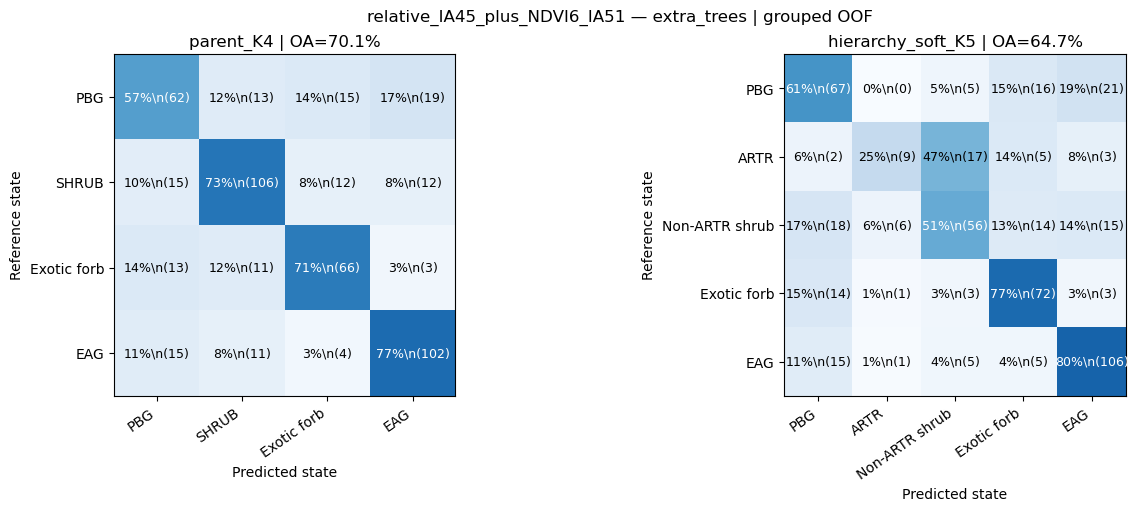

In [9]:
# Confusion matrices (counts) on matched held-out observations.
FEATURE_TO_SHOW = 'relative_IA45_plus_NDVI6_IA51'
MODEL_TO_SHOW = MODELS_TO_RUN[0]
scenario_defs = [('parent_K4',y4,K4_CODES,K4_LABELS),
                 ('hierarchy_soft_K5',y5,K5_CODES,K5_LABELS)]
fig,axs=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,(scenario,truth,codes,labels) in zip(axs,scenario_defs):
    pred=OOF[(FEATURE_TO_SHOW,MODEL_TO_SHOW)][scenario]
    cm=confusion_matrix(truth,pred,labels=codes)
    normalized=cm/np.maximum(cm.sum(axis=1,keepdims=True),1)
    ax.imshow(normalized,cmap='Blues',vmin=0,vmax=1)
    for i in range(len(codes)):
        for j in range(len(codes)):
            ax.text(j,i,f'{normalized[i,j]:.0%}\\n({cm[i,j]})',ha='center',va='center',
                    color='white' if normalized[i,j]>.5 else 'black',fontsize=9)
    ax.set_xticks(range(len(codes)),[labels[k] for k in codes],rotation=35,ha='right')
    ax.set_yticks(range(len(codes)),[labels[k] for k in codes])
    ax.set_title(f'{scenario} | OA={accuracy_score(truth,pred):.1%}')
    ax.set_xlabel('Predicted state'); ax.set_ylabel('Reference state')
fig.suptitle(f'{FEATURE_TO_SHOW} — {MODEL_TO_SHOW} | grouped OOF')
plt.show()

## Interpretation and safeguards

- A feature set with fewer than six defined phenology metrics still contributes to evaluation: the undefined features are imputed **using training-fold observations only** and missingness is indicated.
- The six NDVI features are deterministic functions of K2 coefficient and phase values. They can facilitate nonlinear classification but add no independent measurements.
- Preserve the paired fold assignments for all reported comparisons. Optimizing feature subsets against these same folds can overfit model-selection decisions; use a separate test or nested validation for confirmatory claims.
- The K4 parent task is not equivalent to K5. The conditional shrub score uses only true-shrub holdouts and is not the end-to-end hierarchical K5 accuracy.
- Confirm NDVI phase convention and field/raster alignment. This notebook performs no wall-to-wall inference or temporal validation.